# 03 - Data Quality

Checks the integrity of what's stored in `database/market.db`.

**Before trusting any analysis, prove the data is clean.**

Covers:

1. Inventory of tables and row counts
2. `ohlcv` gaps (missing days)
3. Duplicate timestamps
4. Monotonicity of time columns
5. Price sanity (`high >= low`, `high >= close`, ...)
6. Volume sanity (negative or zero)
7. Outlier days (z-score of returns)
8. Coverage of every other table


## Setup

In [1]:
# --- setup --------------------------------------------------------
import sys
sys.path.insert(0, r"D:\Projects\done\eth_bot\eth_bot_v2")

import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DB = Path(r"D:\Projects\done\eth_bot\eth_bot_v2\database\market.db")
DAY = 86_400_000

def sql(q, **p):
    with sqlite3.connect(DB) as c:
        return pd.read_sql_query(q, c, params=p)

pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)
plt.rcParams["figure.figsize"] = (12, 4)

## 1. Table inventory

Every table in the DB, with row count and time range (if a `ts` or `open_time` column exists).

In [2]:
tables = sql(
    "SELECT name FROM sqlite_master WHERE type='table' "
    "AND name NOT LIKE 'sqlite_%' ORDER BY name")["name"].tolist()

rows = []
for t in tables:
    n = sql(f"SELECT COUNT(*) c FROM {t}").c.iloc[0]
    cols = sql(f"PRAGMA table_info({t})")["name"].tolist()
    time_col = next((c for c in ("ts", "open_time") if c in cols), None)
    if time_col and n:
        rng = sql(f"SELECT MIN({time_col}) a, MAX({time_col}) b FROM {t}").iloc[0]
        a = pd.to_datetime(rng.a, unit="ms").date() if pd.notna(rng.a) else None
        b = pd.to_datetime(rng.b, unit="ms").date() if pd.notna(rng.b) else None
        rows.append((t, n, str(a), str(b)))
    else:
        rows.append((t, n, "-", "-"))

pd.DataFrame(rows, columns=["table", "rows", "from", "to"])

,table,rows,from,to
0,_schema_version,13,-,-
1,fear_greed,2000,2021-04-12,2026-10-03
2,funding_rate,500,2026-04-20,2026-10-03
3,greeks,1,2026-10-03,2026-10-03
4,implied_volatility,200,2026-10-03,2026-10-03
5,liquidations,3,2026-10-03,2026-10-03
6,news,2,2026-10-03,2026-10-03
7,ohlcv,2189,2020-10-05,2026-10-02
8,onchain,3,2026-10-03,2026-10-03
9,open_interest,30,2026-09-04,2026-10-03


## 2. Gaps in `ohlcv`

Daily candles should be one per calendar day. Any step ≠ 1 day
is a gap — either a real market closure (rare for crypto) or a
fetch that skipped a window.

In [3]:
t = sql("SELECT open_time FROM ohlcv "
        "WHERE symbol='ETHUSDT' AND timeframe='1d' ORDER BY open_time")
times = t.open_time.tolist()

gaps = []
for i in range(1, len(times)):
    d = (times[i] - times[i-1]) // DAY
    if d != 1:
        gaps.append({
            "from": pd.to_datetime(times[i-1], unit="ms").date(),
            "to":   pd.to_datetime(times[i],   unit="ms").date(),
            "missing_days": int(d - 1),
        })

print(f"rows       : {len(times)}")
print(f"first      : {pd.to_datetime(times[0],  unit='ms').date()}")
print(f"last       : {pd.to_datetime(times[-1], unit='ms').date()}")
print(f"gap count  : {len(gaps)}")

if gaps:
    display(pd.DataFrame(gaps))
else:
    print("no gaps ✓")

rows       : 2189
first      : 2020-10-05
last       : 2026-10-02
gap count  : 0
no gaps ✓


## 3. Duplicate timestamps

Primary key prevents dupes in normal operation, but let's confirm
no direct insert slipped through.

In [4]:
dupes = sql("""SELECT open_time, COUNT(*) AS n
                 FROM ohlcv
                 WHERE symbol='ETHUSDT' AND timeframe='1d'
                 GROUP BY open_time HAVING n > 1""")
print(f"duplicate open_time values: {len(dupes)}")
dupes

duplicate open_time values: 0


,open_time,n


## 4. Time monotonicity

Every time column must strictly increase when sorted.
If `differences <= 0` appear anywhere, rows are out of order or repeated.

In [5]:
checks = [
    ("ohlcv",           "open_time"),
    ("trades",          "ts"),
    ("funding_rate",    "ts"),
    ("open_interest",   "ts"),
    ("fear_greed",      "ts"),
    ("orderbook",       "ts"),
    ("liquidations",    "ts"),
    ("option_chain",    "ts"),
]

for table, col in checks:
    try:
        v = sql(f"SELECT {col} FROM {table} ORDER BY {col}")[col]
    except Exception as e:
        print(f"  {table:<18} skip ({e})")
        continue
    if len(v) < 2:
        print(f"  {table:<18} rows={len(v)} (too few to check)")
        continue
    d = v.diff().dropna()
    bad = int((d <= 0).sum())
    mark = "ok" if bad == 0 else "FAIL"
    print(f"  {table:<18} rows={len(v):>5}  non-increasing={bad}   [{mark}]")

  ohlcv              rows= 2189  non-increasing=0   [ok]
  trades             rows= 1000  non-increasing=851   [FAIL]
  funding_rate       rows=  500  non-increasing=0   [ok]
  open_interest      rows=   30  non-increasing=0   [ok]
  fear_greed         rows= 2000  non-increasing=0   [ok]
  orderbook          rows=   20  non-increasing=0   [ok]
  liquidations       rows=    3  non-increasing=0   [ok]
  option_chain       rows=  200  non-increasing=199   [FAIL]


## 5. OHLCV price sanity

Rules that must always hold:

- `high >= low`
- `high >= open`, `high >= close`
- `low  <= open`, `low  <= close`
- all prices > 0
- `volume >= 0`

In [6]:
bad = sql("""
    SELECT COUNT(*) AS n FROM ohlcv
    WHERE symbol='ETHUSDT' AND timeframe='1d'
      AND ( high < low
         OR high < open  OR high < close
         OR low  > open  OR low  > close
         OR open <= 0 OR high <= 0 OR low <= 0 OR close <= 0
         OR volume < 0 )
""").n.iloc[0]
print(f"violations: {bad}")

if bad:
    display(sql("""
        SELECT * FROM ohlcv
        WHERE symbol='ETHUSDT' AND timeframe='1d'
          AND ( high < low
             OR high < open  OR high < close
             OR low  > open  OR low  > close
             OR open <= 0 OR high <= 0 OR low <= 0 OR close <= 0
             OR volume < 0 )
        LIMIT 20
    """))

violations: 0


## 6. Volume distribution

Spot zero-volume days or absurd spikes.

zero-volume days: 0


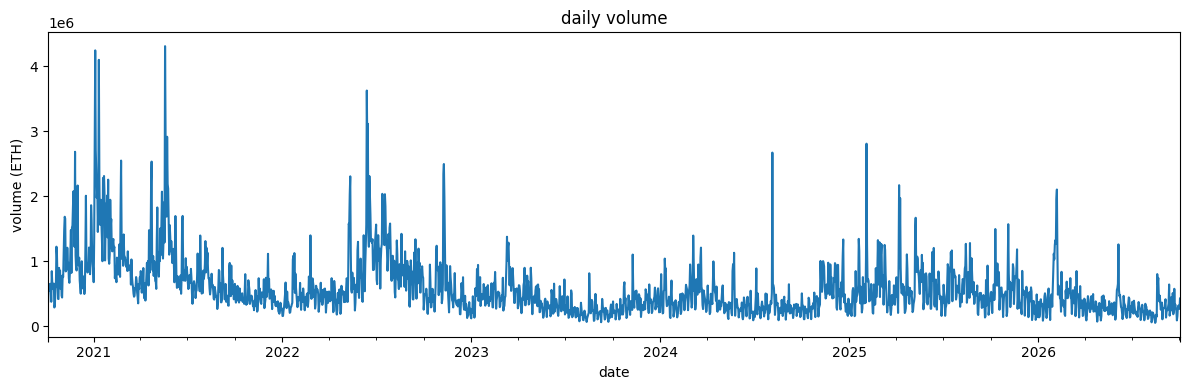

In [7]:
vol = sql("SELECT open_time, volume FROM ohlcv "
          "WHERE symbol='ETHUSDT' AND timeframe='1d' ORDER BY open_time")
vol["date"] = pd.to_datetime(vol.open_time, unit="ms")

zero = vol[vol.volume == 0]
print(f"zero-volume days: {len(zero)}")
if len(zero):
    display(zero.head(20))

fig, ax = plt.subplots(figsize=(12, 4))
vol.set_index("date")["volume"].plot(ax=ax, title="daily volume")
ax.set_ylabel("volume (ETH)")
plt.tight_layout()
plt.show()

## 7. Outlier days (|z| > 4)

Days whose return is more than 4 standard deviations from the mean.

These are the **news days** — ETF approvals, exchange failures, halvings,
macro prints. Real, not errors, but worth eyeballing.

In [8]:
px = sql("SELECT open_time, close FROM ohlcv "
         "WHERE symbol='ETHUSDT' AND timeframe='1d' ORDER BY open_time")
px["date"] = pd.to_datetime(px.open_time, unit="ms")
px = px.set_index("date")["close"]

r = px.pct_change().dropna()
z = (r - r.mean()) / r.std(ddof=0)

big = z[z.abs() > 4].sort_values(key=abs, ascending=False)
out = pd.DataFrame({
    "date":   big.index.date,
    "return": r.loc[big.index].values,
    "z":      big.values,
})
out["return"] = out["return"].map("{:+.2%}".format)
out["z"]      = out["z"].map("{:+.2f}".format)
print(f"outlier days: {len(out)}")
out

outlier days: 11


,date,return,z
0,2021-05-19,-27.74%,-6.91
1,2021-05-24,+26.33%,+6.48
2,2021-01-03,+26.30%,+6.47
3,2025-05-08,+21.88%,+5.38
4,2021-01-21,-19.32%,-4.83
5,2024-05-20,+19.23%,+4.72
6,2022-07-18,+18.11%,+4.44
7,2022-11-10,+17.82%,+4.37
8,2022-11-09,-17.38%,-4.35
9,2026-08-19,+17.46%,+4.28


## 8. Coverage of other tables

For each table with a time column, show:

- first and last row
- days of coverage
- expected rows vs actual (for daily-cadence tables)

In [9]:
coverage = []
for table, col in [
    ("funding_rate",  "ts"),
    ("open_interest", "ts"),
    ("fear_greed",    "ts"),
    ("trades",        "ts"),
    ("orderbook",     "ts"),
    ("option_chain",  "ts"),
]:
    try:
        row = sql(f"SELECT MIN({col}) a, MAX({col}) b, COUNT(*) n FROM {table}").iloc[0]
    except Exception:
        continue
    if pd.isna(row.a):
        coverage.append((table, 0, "-", "-", "-"))
        continue
    a = pd.to_datetime(row.a, unit="ms").date()
    b = pd.to_datetime(row.b, unit="ms").date()
    span = (b - a).days + 1
    coverage.append((table, int(row.n), str(a), str(b), span))

pd.DataFrame(coverage, columns=["table", "rows", "from", "to", "days_span"])

,table,rows,from,to,days_span
0,funding_rate,500,2026-04-20,2026-10-03,167
1,open_interest,30,2026-09-04,2026-10-03,30
2,fear_greed,2000,2021-04-12,2026-10-03,2001
3,trades,1000,2026-10-03,2026-10-03,1
4,orderbook,20,2026-10-03,2026-10-03,1
5,option_chain,200,2026-10-03,2026-10-03,1


## Verdict

Run all cells top to bottom.

The dataset is **trustworthy** if:

- gap count = 0
- duplicate count = 0
- all monotonicity checks pass
- OHLCV price violations = 0
- zero-volume days are rare and explainable

If any check fails, fix that first — every downstream analysis
depends on this data being clean.

In [10]:
print("checklist:")
print(f"  ohlcv gaps          : {len(gaps)}")
print(f"  ohlcv duplicates    : {len(dupes)}")
print(f"  price violations    : {bad}")
print(f"  zero-volume days    : {len(zero)}")
print(f"  outlier days (|z|>4): {len(out)}")
print()
if len(gaps) == 0 and len(dupes) == 0 and bad == 0:
    print("data is clean ✓")
else:
    print("see cells above for details")

checklist:
  ohlcv gaps          : 0
  ohlcv duplicates    : 0
  price violations    : 0
  zero-volume days    : 0
  outlier days (|z|>4): 11

data is clean ✓


## Next steps

- **Fix gaps** (if any): `python -m scripts_python.update_market`
  will back-fill automatically.
- **Returns & vol**: `02_returns_vol.ipynb`
- **Cross-source**: `04_funding_oi.ipynb`
